# Multilabel Emotion Classification

NLP Project – Section 7MA1 – Group 3

------

- Mohammed Firas Sawab (leader)
- Rashed Ali Alkhathlan
- Qasim Mustafa Al-Mahfoodh

Input: an English comment.

Output: one or more of 7 emotions (anger, disgust, fear, joy, sadness, surprise, neutral).

Question: which of three approaches (TF-IDF with logistic regression, an RNN with pretrained GPT-2 embeddings,
or fine-tuned RoBERTa) recognises emotions, and especially the rare ones (fear and disgust), most reliably,
measured by macro F1 and exact-match accuracy on the same test set?

How to run: Google Colab -> Runtime -> Change runtime type -> T4 GPU -> Run all (about 45 min).

## 1. Setup

In [1]:
!pip install -q kagglehub

In [2]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import sklearn
import transformers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = 'cuda' if torch.cuda.is_available() else 'cpu'

# package versions (for reproducibility)
print("torch       ", torch.__version__)
print("transformers", transformers.__version__)
print("sklearn     ", sklearn.__version__)
print("pandas      ", pd.__version__)
print("device      ", device)

torch        2.14.1+cu130
transformers 5.22.1
sklearn      1.6.1
pandas       2.2.3
device       cuda


## 2. Data

In [3]:
import kagglehub
import pathlib

path = kagglehub.dataset_download("debarshichanda/goemotions")
data_path = pathlib.Path(path) / 'data'
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'goemotions' dataset.
Path to dataset files: /kaggle/input/goemotions


In [4]:
cols = ['text', 'class', 'commentid']
train_df = pd.read_csv(data_path / 'train.tsv', delimiter='\t', header=None, names=cols)
dev_df   = pd.read_csv(data_path / 'dev.tsv',   delimiter='\t', header=None, names=cols)
test_df  = pd.read_csv(data_path / 'test.tsv',  delimiter='\t', header=None, names=cols)

print(f"Train set: {len(train_df)}\nDev set: {len(dev_df)}\nTest set: {len(test_df)}")
train_df.head()

Train set: 43410
Dev set: 5426
Test set: 5427


,text,class,commentid
0,My favourite food is anything I didn't have to...,27,eebbqej
1,"Now if he does off himself, everyone will thin...",27,ed00q6i
2,WHY THE FUCK IS BAYLESS ISOING,2,eezlygj
3,To make her feel threatened,14,ed7ypvh
4,Dirty Southern Wankers,3,ed0bdzj


### Map the 28 emotions to 7 Ekman groups

In [5]:
emotions = [ #all 27 emotions + neutral in the ds
    "admiration", "amusement", "anger", "annoyance", "approval", "caring",
    "confusion", "curiosity", "desire", "disappointment", "disapproval",
    "disgust", "embarrassment", "excitement", "fear", "gratitude", "grief",
    "joy", "love", "nervousness", "optimism", "pride", "realization",
    "relief", "remorse", "sadness", "surprise", "neutral"
]

ekman_mapping = {
    "anger":    ["anger", "annoyance", "disapproval"],
    "disgust":  ["disgust"],
    "fear":     ["fear", "nervousness"],
    "joy":      ["joy", "amusement", "approval", "excitement", "gratitude", "love",
                 "optimism", "relief", "pride", "admiration", "desire", "caring"],
    "sadness":  ["sadness", "disappointment", "embarrassment", "grief", "remorse"],
    "surprise": ["surprise", "realization", "confusion", "curiosity"],
    "neutral":  ["neutral"],
}

EKMAN = list(ekman_mapping.keys()) #7 groups

emotion_to_group = {}
for group, small_emotions in ekman_mapping.items():
    for emotion in small_emotions:
        emotion_to_group[emotion] = group


# convert "0, 18" -> admiration, love -> both are joy -> ["joy"]
def to_ekman(label_text):
    groups = []
    for number in label_text.split(","):   # "0,18" -> ["0", "18"]
        emotion = emotions[int(number)]    # 18 -> "love"
        group = emotion_to_group[emotion]  # "love" -> "joy"
        if group not in groups:            # avoid ["joy", "joy"]
            groups.append(group)
    return sorted(groups)


train_df["ekman"] = train_df["class"].apply(to_ekman)
dev_df["ekman"]   = dev_df["class"].apply(to_ekman)
test_df["ekman"]  = test_df["class"].apply(to_ekman)

### Duplicate check
The same comment must not appear in two splits. We remove dev/test comments whose text
(lower-cased) already appears in the training set (and test comments that appear in dev).

In [6]:
train_texts = set(train_df['text'].str.lower().str.strip())
dev_texts   = set(dev_df['text'].str.lower().str.strip())

dev_is_dup  = dev_df['text'].str.lower().str.strip().isin(train_texts)
test_is_dup = test_df['text'].str.lower().str.strip().isin(train_texts | dev_texts)

print("Dev comments also in train:", dev_is_dup.sum())
print("Test comments also in train/dev:", test_is_dup.sum())
print("Examples:", list(test_df[test_is_dup]['text'][:6]))

dev_df  = dev_df[~dev_is_dup].reset_index(drop=True)
test_df = test_df[~test_is_dup].reset_index(drop=True)
print(f"\nAfter cleaning -> Train: {len(train_df)} | Dev: {len(dev_df)} | Test: {len(test_df)}")

Dev comments also in train: 49
Test comments also in train/dev: 48
Examples: ['You’re welcome', 'thank you !', 'Sounds good.', '[NAME].', 'How do you know this?', 'Thank you.']

After cleaning -> Train: 43410 | Dev: 5377 | Test: 5379


In [7]:
from sklearn.preprocessing import MultiLabelBinarizer

# MultiLabelBinarizer turns ["anger", "sadness"] into
# [1, 0, 0, 0, 0, 1, 0]  (one column per Ekman group)
labeler = MultiLabelBinarizer(classes=EKMAN)

y_train = labeler.fit_transform(train_df['ekman'])
y_dev   = labeler.transform(dev_df['ekman'])
y_test  = labeler.transform(test_df['ekman'])

counts = pd.DataFrame({'train': y_train.sum(axis=0),
                       'dev':   y_dev.sum(axis=0),
                       'test':  y_test.sum(axis=0)}, index=EKMAN)
counts

,train,dev,test
anger,5579,714,726
disgust,793,96,122
fear,726,104,97
joy,17410,2186,2072
sadness,3263,389,377
surprise,5367,620,676
neutral,14219,1759,1775


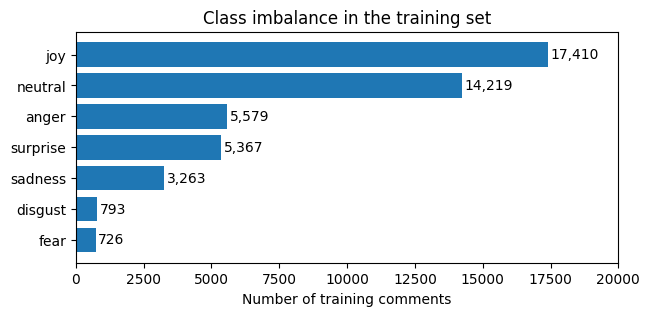

In [8]:
# class imbalance plot
train_counts = counts['train'].sort_values()

plt.figure(figsize=(7, 3))
plt.barh(train_counts.index, train_counts.values)
for i, value in enumerate(train_counts.values):
    plt.text(value + 100, i, f"{value:,}", va="center")
plt.xlim(0, 20000)
plt.xlabel("Number of training comments")
plt.title("Class imbalance in the training set")
plt.show()

### Evaluation helper
Every model is tested on the **same** test set with:
- **accuracy** (exact match: all 7 labels must be right)
- **macro F1** (average F1 over the 7 classes, so rare classes count as much as joy)

In [9]:
from sklearn.metrics import classification_report, f1_score, accuracy_score

results = {}     # model name -> scores
per_class = {}   # model name -> F1 of each class
test_preds = {}  # model name -> predictions on the test set

def evaluate(name, dev_pred, test_pred):
    dev_f1   = f1_score(y_dev, dev_pred, average='macro', zero_division=0)
    test_f1  = f1_score(y_test, test_pred, average='macro', zero_division=0)
    test_acc = accuracy_score(y_test, test_pred)

    results[name] = {'dev macro F1': dev_f1, 'test macro F1': test_f1, 'test accuracy': test_acc}
    per_class[name] = dict(zip(EKMAN, f1_score(y_test, test_pred, average=None, zero_division=0)))
    test_preds[name] = test_pred

    print(f"{name}\n  dev macro F1 = {dev_f1:.3f} | test macro F1 = {test_f1:.3f} | test accuracy = {test_acc:.2%}\n")
    print(classification_report(y_test, test_pred, target_names=EKMAN, zero_division=0))

## 3. Method 1: TF-IDF word and bigram features + logistic regression

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

tf_vectorizer = TfidfVectorizer(ngram_range=(1, 2)) # unigrams and bigrams
tf_vectorizer.fit(train_df['text'])                 # fit on TRAIN only

X_train = tf_vectorizer.transform(train_df['text'])
X_dev   = tf_vectorizer.transform(dev_df['text'])
X_test  = tf_vectorizer.transform(test_df['text'])

X_train.shape, y_train.shape

((43410, 238836), (43410, 7))

In [11]:
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression

# OneVsRestClassifier trains one LogisticRegression per column of y_train
# -> 7 separate yes/no models, one for each Ekman group.
# We choose C (regularisation) on the dev set.

best_C, best_dev_f1 = None, 0
for C in [0.5, 1, 2, 4]:
    clf = OneVsRestClassifier(LogisticRegression(C=C, max_iter=1000, class_weight='balanced'))
    clf.fit(X_train, y_train)
    dev_f1 = f1_score(y_dev, clf.predict(X_dev), average='macro', zero_division=0)
    print(f"C = {C}: dev macro F1 = {dev_f1:.4f}")
    if dev_f1 > best_dev_f1:
        best_C, best_dev_f1 = C, dev_f1

print("Best C on dev:", best_C)

C = 0.5: dev macro F1 = 0.5374
C = 1: dev macro F1 = 0.5426
C = 2: dev macro F1 = 0.5486
C = 4: dev macro F1 = 0.5512
Best C on dev: 4


In [12]:
tfidf_model = OneVsRestClassifier(LogisticRegression(C=best_C, max_iter=1000, class_weight='balanced'))
tfidf_model.fit(X_train, y_train)

evaluate('TF-IDF + LogReg', tfidf_model.predict(X_dev), tfidf_model.predict(X_test))

TF-IDF + LogReg
  dev macro F1 = 0.551 | test macro F1 = 0.565 | test accuracy = 47.43%

              precision    recall  f1-score   support

       anger       0.45      0.53      0.49       726
     disgust       0.47      0.47      0.47       122
        fear       0.56      0.61      0.58        97
         joy       0.78      0.77      0.77      2072
     sadness       0.50      0.54      0.52       377
    surprise       0.45      0.58      0.50       676
     neutral       0.59      0.66      0.62      1775

   micro avg       0.60      0.66      0.63      5845
   macro avg       0.54      0.59      0.57      5845
weighted avg       0.61      0.66      0.63      5845
 samples avg       0.60      0.67      0.62      5845



## 4. Method 3: Fine-tuned RoBERTa (pretrained model)

We load `roberta-base` with a new 7-output head and train the whole model for 3 epochs.

We try it with and without class weights, and choose the version with the best dev macro F1.

In [13]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

r_tokenizer = AutoTokenizer.from_pretrained('roberta-base')

def make_loader(df, y, shuffle):
    enc = r_tokenizer(list(df['text']), truncation=True, max_length=48, padding='max_length', return_tensors='pt')
    data = TensorDataset(enc['input_ids'], enc['attention_mask'], torch.tensor(y, dtype=torch.float))
    return DataLoader(data, batch_size=32, shuffle=shuffle)

r_train = make_loader(train_df, y_train, shuffle=True)
r_dev   = make_loader(dev_df,   y_dev,   shuffle=False)
r_test  = make_loader(test_df,  y_test,  shuffle=False)

# class weights: (number of negatives / number of positives) for each class
pos_counts = y_train.sum(axis=0)
pos_weight = torch.tensor((len(y_train) - pos_counts) / pos_counts, dtype=torch.float).to(device)
gentle_pos_weight = pos_weight.sqrt()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [14]:
from tqdm.notebook import tqdm

@torch.no_grad()
def roberta_predict(model, loader):
    model.eval()
    preds = []
    for ids, mask, _ in loader:
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(input_ids=ids.to(device), attention_mask=mask.to(device)).logits
        preds.append((torch.sigmoid(logits) > 0.5).int().cpu())
    return torch.cat(preds).numpy()


def run(name, freeze, epochs, lr, weights=None):
    torch.manual_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(
        'roberta-base', num_labels=7, problem_type='multi_label_classification').to(device)

    if freeze:   # only train the classification head
        for p in model.roberta.parameters():
            p.requires_grad = False

    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=weights)   # None = no class weighting
    scaler = torch.amp.GradScaler('cuda')

    # train
    for epoch in range(epochs):
        model.train()
        for ids, mask, y in tqdm(r_train):
            with torch.autocast("cuda", dtype=torch.float16):
                logits = model(input_ids=ids.to(device), attention_mask=mask.to(device)).logits
            loss = loss_fn(logits.float(), y.to(device))

            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()

    # evaluate on dev and test
    evaluate(name, roberta_predict(model, r_dev), roberta_predict(model, r_test))
    return model

In [15]:
finetuned_model = run('RoBERTa fine-tuned', freeze=False, epochs=3, lr=2e-5)

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  0%|          | 0/1357 [00:00<?, ?it/s]

  0%|          | 0/1357 [00:00<?, ?it/s]

  0%|          | 0/1357 [00:00<?, ?it/s]

RoBERTa fine-tuned
  dev macro F1 = 0.612 | test macro F1 = 0.628 | test accuracy = 59.96%

              precision    recall  f1-score   support

       anger       0.54      0.61      0.58       726
     disgust       0.68      0.36      0.47       122
        fear       0.64      0.72      0.68        97
         joy       0.83      0.84      0.83      2072
     sadness       0.71      0.56      0.63       377
    surprise       0.56      0.67      0.61       676
     neutral       0.74      0.51      0.61      1775

   micro avg       0.71      0.66      0.69      5845
   macro avg       0.67      0.61      0.63      5845
weighted avg       0.72      0.66      0.68      5845
 samples avg       0.68      0.68      0.67      5845



In [16]:
finetuned_weighted_model = run('RoBERTa fine-tuned + gentle weights', freeze=False, epochs=3, lr=2e-5, weights=gentle_pos_weight)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  0%|          | 0/1357 [00:00<?, ?it/s]

  0%|          | 0/1357 [00:00<?, ?it/s]

  0%|          | 0/1357 [00:00<?, ?it/s]

RoBERTa fine-tuned + gentle weights
  dev macro F1 = 0.608 | test macro F1 = 0.617 | test accuracy = 52.67%

              precision    recall  f1-score   support

       anger       0.45      0.77      0.57       726
     disgust       0.37      0.68      0.48       122
        fear       0.46      0.86      0.59        97
         joy       0.82      0.85      0.83      2072
     sadness       0.52      0.68      0.59       377
    surprise       0.49      0.78      0.60       676
     neutral       0.68      0.64      0.66      1775

   micro avg       0.62      0.75      0.68      5845
   macro avg       0.54      0.75      0.62      5845
weighted avg       0.66      0.75      0.69      5845
 samples avg       0.68      0.76      0.70      5845



In [17]:
# choose the final RoBERTa using the dev set
if results['RoBERTa fine-tuned']['dev macro F1'] >= results['RoBERTa fine-tuned + gentle weights']['dev macro F1']:
    BEST_ROBERTA = 'RoBERTa fine-tuned'
    roberta_model = finetuned_model
    del finetuned_weighted_model
else:
    BEST_ROBERTA = 'RoBERTa fine-tuned + gentle weights'
    roberta_model = finetuned_weighted_model
    del finetuned_model

torch.cuda.empty_cache()
print("Chosen on dev:", BEST_ROBERTA)

Chosen on dev: RoBERTa fine-tuned


## 5. Method 2 and extra experiments
These explain why finetuning matters.

### 5.1 Frozen RoBERTa (only the classification head is trained)

In [18]:
frozen_model = run('RoBERTa frozen', freeze=True, epochs=3, lr=1e-3)
del frozen_model

frozen_weighted_model = run('RoBERTa frozen + full weights', freeze=True, epochs=3, lr=1e-3, weights=pos_weight)
del frozen_weighted_model
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  0%|          | 0/1357 [00:00<?, ?it/s]

  0%|          | 0/1357 [00:00<?, ?it/s]

  0%|          | 0/1357 [00:00<?, ?it/s]

RoBERTa frozen
  dev macro F1 = 0.235 | test macro F1 = 0.233 | test accuracy = 32.46%

              precision    recall  f1-score   support

       anger       0.64      0.09      0.16       726
     disgust       0.00      0.00      0.00       122
        fear       0.00      0.00      0.00        97
         joy       0.75      0.65      0.70      2072
     sadness       0.75      0.01      0.02       377
    surprise       0.54      0.45      0.49       676
     neutral       0.73      0.16      0.27      1775

   micro avg       0.70      0.35      0.46      5845
   macro avg       0.49      0.20      0.23      5845
weighted avg       0.68      0.35      0.41      5845
 samples avg       0.37      0.35      0.36      5845



... (2 outputs left out)

  0%|          | 0/1357 [00:00<?, ?it/s]

  0%|          | 0/1357 [00:00<?, ?it/s]

  0%|          | 0/1357 [00:00<?, ?it/s]

RoBERTa frozen + full weights
  dev macro F1 = 0.410 | test macro F1 = 0.416 | test accuracy = 23.41%

              precision    recall  f1-score   support

       anger       0.28      0.83      0.42       726
     disgust       0.14      0.57      0.23       122
        fear       0.14      0.71      0.24        97
         joy       0.64      0.82      0.72      2072
     sadness       0.24      0.65      0.35       377
    surprise       0.24      0.87      0.37       676
     neutral       0.59      0.58      0.59      1775

   micro avg       0.39      0.74      0.51      5845
   macro avg       0.32      0.72      0.42      5845
weighted avg       0.49      0.74      0.56      5845
 samples avg       0.47      0.74      0.54      5845



### 5.2 Method 2: Pretrained GPT-2 embeddings + simple RNN

In [19]:
gpt_tokenizer = AutoTokenizer.from_pretrained('gpt2')
PAD = gpt_tokenizer.eos_token_id
gpt_tokenizer.pad_token_id = PAD
vocab_size = len(gpt_tokenizer)

def make_gpt_loader(df, y, shuffle, batch_size=1024):
    enc = gpt_tokenizer(list(df['text']), truncation=True, max_length=30, padding='max_length', return_tensors='pt')
    data = TensorDataset(enc['input_ids'], torch.tensor(y, dtype=torch.float))
    return DataLoader(data, batch_size=batch_size, shuffle=shuffle)

g_train = make_gpt_loader(train_df, y_train, shuffle=True)
g_dev   = make_gpt_loader(dev_df,   y_dev,   shuffle=False)
g_test  = make_gpt_loader(test_df,  y_test,  shuffle=False, batch_size=256)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [20]:
class RNN_Classifier(nn.Module):
    def __init__(self, embed_dim, hidden_state_dim=128):
        super().__init__()
        self.hidden_state_dim = hidden_state_dim
        self.embed = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embed_dim)
        self.W_x = nn.Linear(embed_dim, hidden_state_dim, bias=False)
        self.W_h = nn.Linear(hidden_state_dim, hidden_state_dim, bias=True)
        self.out = nn.Linear(hidden_state_dim, 7) #for ekman labels
        self.tanh = nn.Tanh()

    def forward(self, x):
        is_real_token = (x != PAD)

        x = self.embed(x)
        b, seq, e = x.shape

        h_t = torch.zeros((b, self.hidden_state_dim), device=device)

        for t in range(seq):
            token = x[:, t, :]
            h_new = self.tanh(self.W_x(token) + self.W_h(h_t))
            keep = is_real_token[:, t].view(-1, 1)
            h_t = torch.where(keep, h_new, h_t)   # padding does not change the hidden state

        logits = self.out(h_t)
        return logits


@torch.no_grad()
def rnn_predict(model, loader):
    model.eval()
    preds = []
    for x, _ in loader:
        logits = model(x.to(device))
        preds.append((torch.sigmoid(logits) > 0.5).int().cpu())
    return torch.cat(preds).numpy()


def train_rnn(model, optimizer, loss_fn, epochs=30):
    lr_sched = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)
    for epoch in range(epochs):
        model.train()
        for x, y in g_train:
            loss = loss_fn(model(x.to(device)), y.to(device))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        lr_sched.step()

        if (epoch + 1) % 5 == 0:
            dev_f1 = f1_score(y_dev, rnn_predict(model, g_dev), average='macro', zero_division=0)
            print(f"epoch {epoch+1} | dev macro F1 {dev_f1:.3f}")

In [21]:
# random embeddings, no class weights
torch.manual_seed(SEED)

rnn = RNN_Classifier(embed_dim=256, hidden_state_dim=784).to(device)
optimizer = torch.optim.AdamW(rnn.parameters(), lr=4e-3, weight_decay=1e-4)
train_rnn(rnn, optimizer, nn.BCEWithLogitsLoss())

evaluate('RNN (from scratch)', rnn_predict(rnn, g_dev), rnn_predict(rnn, g_test))

epoch 5 | dev macro F1 0.149
epoch 10 | dev macro F1 0.256
epoch 15 | dev macro F1 0.306
epoch 20 | dev macro F1 0.326
epoch 25 | dev macro F1 0.332
epoch 30 | dev macro F1 0.335
RNN (from scratch)
  dev macro F1 = 0.335 | test macro F1 = 0.336 | test accuracy = 40.64%

              precision    recall  f1-score   support

       anger       0.32      0.23      0.27       726
     disgust       0.37      0.14      0.20       122
        fear       0.30      0.06      0.10        97
         joy       0.69      0.70      0.70      2072
     sadness       0.30      0.21      0.25       377
    surprise       0.38      0.32      0.35       676
     neutral       0.49      0.48      0.48      1775

   micro avg       0.53      0.48      0.50      5845
   macro avg       0.41      0.31      0.34      5845
weighted avg       0.51      0.48      0.49      5845
 samples avg       0.48      0.49      0.48      5845



In [22]:
# trainable GPT-2 token embeddings + class weights
from transformers import GPT2Model

gpt2_emb = GPT2Model.from_pretrained('gpt2').wte.weight.detach()   # shape (50257, 768)

torch.manual_seed(SEED)

rnn_gpt = RNN_Classifier(embed_dim=768, hidden_state_dim=784)
rnn_gpt.embed = nn.Embedding.from_pretrained(gpt2_emb, freeze=False)   # replaces the random embedding
rnn_gpt = rnn_gpt.to(device)

optimizer = torch.optim.AdamW([
    {"params": rnn_gpt.embed.parameters(), "lr": 1e-4},
    {"params": [p for name, p in rnn_gpt.named_parameters() if not name.startswith("embed")], "lr": 4e-3},
], weight_decay=1e-4)
train_rnn(rnn_gpt, optimizer, nn.BCEWithLogitsLoss(pos_weight=pos_weight))

evaluate('RNN + GPT-2 embeddings', rnn_predict(rnn_gpt, g_dev), rnn_predict(rnn_gpt, g_test))

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

epoch 5 | dev macro F1 0.241
epoch 10 | dev macro F1 0.194
epoch 15 | dev macro F1 0.214
epoch 20 | dev macro F1 0.324
epoch 25 | dev macro F1 0.315
epoch 30 | dev macro F1 0.326
RNN + GPT-2 embeddings
  dev macro F1 = 0.326 | test macro F1 = 0.335 | test accuracy = 2.92%

              precision    recall  f1-score   support

       anger       0.27      0.47      0.35       726
     disgust       0.08      0.70      0.15       122
        fear       0.07      0.74      0.13        97
         joy       0.48      0.84      0.61      2072
     sadness       0.20      0.60      0.30       377
    surprise       0.28      0.35      0.31       676
     neutral       0.36      0.80      0.50      1775

   micro avg       0.32      0.71      0.44      5845
   macro avg       0.25      0.64      0.34      5845
weighted avg       0.36      0.71      0.47      5845
 samples avg       0.35      0.72      0.46      5845



## 6. Results (all on the same test set)

In [23]:
results_df = pd.DataFrame(results).T.sort_values('test macro F1', ascending=False)
results_df.round(3)

,dev macro F1,test macro F1,test accuracy
RoBERTa fine-tuned,0.612,0.628,0.600
RoBERTa fine-tuned + gentle weights,0.608,0.617,0.527
TF-IDF + LogReg,0.551,0.565,0.474
RoBERTa frozen + full weights,0.410,0.416,0.234
RNN (from scratch),0.335,0.336,0.406
RNN + GPT-2 embeddings,0.326,0.335,0.029
RoBERTa frozen,0.235,0.233,0.325


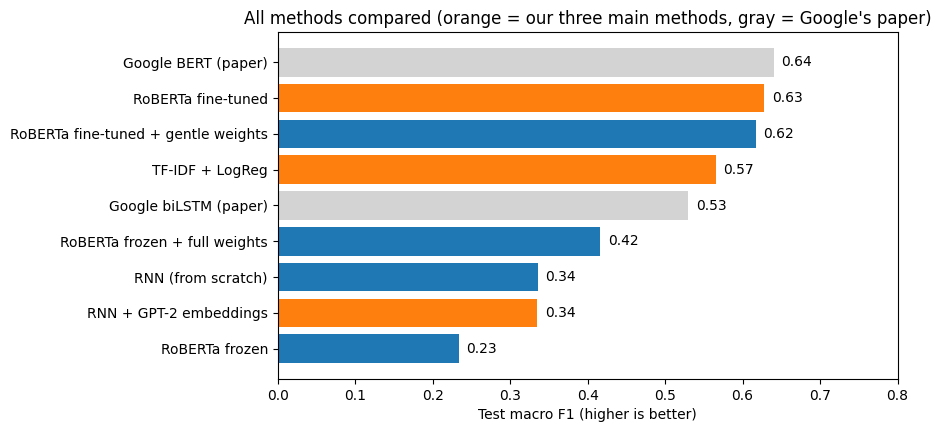

In [24]:
scores = results_df['test macro F1'].to_dict()

# Google's published results for the same 7 Ekman groups (Demszky et al., 2020)
# BERT: Table 6 of the paper | biLSTM: Section 5.4 of the paper
scores["Google BERT (paper)"] = 0.64
scores["Google biLSTM (paper)"] = 0.53

scores = pd.Series(scores).sort_values()
colors = []
for name in scores.index:
    if name.startswith("Google"):
        colors.append("lightgray")
    elif name in ['TF-IDF + LogReg', 'RNN + GPT-2 embeddings', BEST_ROBERTA]:
        colors.append("tab:orange")
    else:
        colors.append("tab:blue")

plt.figure(figsize=(8, 4.5))
plt.barh(scores.index, scores.values, color=colors)

for i, score in enumerate(scores.values):
    plt.text(score + 0.01, i, f"{score:.2f}", va="center")

plt.xlim(0, 0.8)
plt.xlabel("Test macro F1 (higher is better)")

plt.title("All methods compared (orange = our three main methods, gray = Google's paper)")

plt.show()

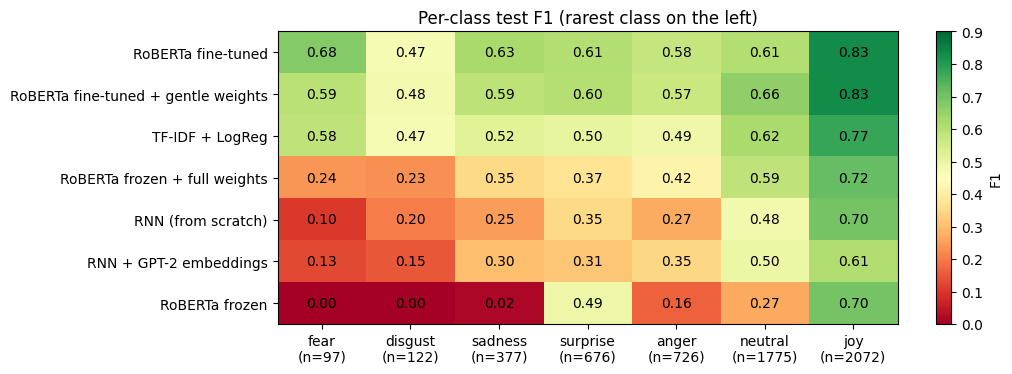

In [25]:
classes = list(counts['test'].sort_values().index)   # rarest class first
models = list(results_df.index)
table = [[per_class[m][c] for c in classes] for m in models]

plt.figure(figsize=(10, 3.8))

plt.imshow(table, cmap="RdYlGn", vmin=0, vmax=0.9, aspect="auto")
plt.colorbar(label="F1")

plt.xticks(range(len(classes)), [f"{c}\n(n={counts['test'][c]})" for c in classes])
plt.yticks(range(len(models)), models)

for row in range(len(models)):
    for col in range(len(classes)):
        plt.text(col, row, f"{table[row][col]:.2f}", ha="center", va="center")

plt.title("Per-class test F1 (rarest class on the left)")
plt.show()

In [26]:
base = results['TF-IDF + LogReg']
best = results[BEST_ROBERTA]

print(f"TF-IDF + LogReg : macro F1 {base['test macro F1']:.3f} | accuracy {base['test accuracy']:.2%}")
print(f"{BEST_ROBERTA}: macro F1 {best['test macro F1']:.3f} | accuracy {best['test accuracy']:.2%}")
print(f"Improvement in macro F1: {best['test macro F1'] - base['test macro F1']:+.3f}")
print()

for c in ['fear', 'disgust']:
    print(f"{c}: TF-IDF {per_class['TF-IDF + LogReg'][c]:.2f} -> RoBERTa {per_class[BEST_ROBERTA][c]:.2f}")

TF-IDF + LogReg : macro F1 0.565 | accuracy 47.43%
RoBERTa fine-tuned: macro F1 0.628 | accuracy 59.96%
Improvement in macro F1: +0.063

fear: TF-IDF 0.58 -> RoBERTa 0.68
disgust: TF-IDF 0.47 -> RoBERTa 0.47


## 7. Error analysis (real test comments)

In [27]:
def names(row):   # [0,0,1,0,0,0,0] -> "fear"
    return ", ".join(np.array(EKMAN)[row == 1]) or "(none)"

tfidf_pred = test_preds['TF-IDF + LogReg']
roberta_pred = test_preds[BEST_ROBERTA]

tfidf_correct = (tfidf_pred == y_test).all(axis=1)
roberta_correct = (roberta_pred == y_test).all(axis=1)

print("RoBERTa right, TF-IDF wrong:", (roberta_correct & ~tfidf_correct).sum())
print("TF-IDF right, RoBERTa wrong:", (tfidf_correct & ~roberta_correct).sum())
print("Both wrong:                 ", (~tfidf_correct & ~roberta_correct).sum())

def show_examples(mask, n=8):
    rows = np.where(mask)[0]
    rows = np.random.default_rng(SEED).choice(rows, size=min(n, len(rows)), replace=False)

    for i in rows:
        print(test_df['text'][i])
        print(f"   true: {names(y_test[i])} | TF-IDF: {names(tfidf_pred[i])} | RoBERTa: {names(roberta_pred[i])}\n")

RoBERTa right, TF-IDF wrong: 1108
TF-IDF right, RoBERTa wrong: 434
Both wrong:                  1720


In [28]:
print("=== RoBERTa right, TF-IDF wrong ===\n")
show_examples(roberta_correct & ~tfidf_correct)

=== RoBERTa right, TF-IDF wrong ===

Well I'm trying to improve, man 
   true: joy | TF-IDF: neutral | RoBERTa: joy

That's the worst feeling haha
   true: joy | TF-IDF: disgust, joy | RoBERTa: joy

Respect my authoritah! Demanding respect sounds like a guarantee of not getting it.
   true: joy | TF-IDF: anger, joy | RoBERTa: joy

Unfortunately, successful and rich people blame foreigners too :(
   true: sadness | TF-IDF: anger, sadness | RoBERTa: sadness

As an [NAME], I apologize for the cranky old conservatives who are probably making ridiculously uninformed comments about your country right now :/
   true: sadness | TF-IDF: (none) | RoBERTa: sadness

Why? I love it.
   true: joy | TF-IDF: joy, surprise | RoBERTa: joy

He keeps saying this in my playthrough when that's definitely NOT what I'm doing. I just suck at hunting!!
   true: anger | TF-IDF: anger, neutral | RoBERTa: anger

Since you called me out for saying that I am defending the attacker, then just point out which sentence

In [29]:
print("=== Both wrong ===\n")
show_examples(~tfidf_correct & ~roberta_correct)

=== Both wrong ===

Man, never underestimate the power of a crock pot, some frozen chicken, veggies and cottage cheese.
   true: joy | TF-IDF: neutral | RoBERTa: (none)

Pretty sure the legislature needs to change laws
   true: neutral | TF-IDF: joy | RoBERTa: joy

What is a punishment if not an undesirable consequence imposed by others?
   true: neutral | TF-IDF: surprise, neutral | RoBERTa: surprise

Not when you compare it to CW though.
   true: neutral | TF-IDF: anger | RoBERTa: anger, neutral

The worst thing is when you find it in a place you know you looked first.
   true: neutral | TF-IDF: disgust | RoBERTa: disgust

>!I always assume that Motoyasu's team changes once every week or something.!<
   true: joy | TF-IDF: neutral | RoBERTa: neutral

No if anything the exact opposite. Couldn’t be further from the truth
   true: neutral | TF-IDF: anger, neutral | RoBERTa: anger

This, in top of my already terrible mental health, is the reason why I'm severely underweight and need help

## 8. Try it
`predict_emotions` uses the models trained above.

**To try it without retraining:** run Section 1 (Setup), then run from here. The next cell downloads our saved models
from the GitHub release https://github.com/Ephab/NLP-Project/releases/tag/models-v1 (about 460 MB) into a relative
`saved_models/` folder. If the models were trained in this session, it uses those instead.

In [30]:
# Use the models trained above, or download the saved ones if training was skipped (no retraining needed)
if 'roberta_model' not in globals() or 'tfidf_model' not in globals():
    import json, pathlib, urllib.request, zipfile, joblib
    from transformers import AutoTokenizer, AutoModelForSequenceClassification

    SAVE_DIR = pathlib.Path('saved_models')   # relative path
    if not (SAVE_DIR / 'info.json').exists():
        print("Downloading trained models (about 460 MB) from GitHub ...")
        urllib.request.urlretrieve(
            'https://github.com/Ephab/NLP-Project/releases/download/models-v1/saved_models.zip', 'saved_models.zip')
        with zipfile.ZipFile('saved_models.zip') as z:
            z.extractall('.')

    EKMAN = json.load(open(SAVE_DIR / 'info.json'))['labels']
    tfidf = joblib.load(SAVE_DIR / 'tfidf_logreg.joblib')
    tf_vectorizer, tfidf_model = tfidf['vectorizer'], tfidf['model']
    r_tokenizer = AutoTokenizer.from_pretrained(str(SAVE_DIR / 'roberta_finetuned'))
    roberta_model = AutoModelForSequenceClassification.from_pretrained(str(SAVE_DIR / 'roberta_finetuned')).to(device)
    print("Loaded the saved models from the GitHub release.")
else:
    print("Using the models trained above in this session.")

Using the models trained above in this session.


In [31]:
@torch.no_grad()
def predict_emotions(text):
    if not isinstance(text, str) or text.strip() == "":
        print("Please type a non-empty English sentence.")
        return

    # Method 1: TF-IDF + LogReg (columns are in EKMAN order)
    tfidf_pred = tfidf_model.predict(tf_vectorizer.transform([text]))[0]
    tfidf_labels = [EKMAN[i] for i in range(7) if tfidf_pred[i] == 1]

    # Method 3: fine-tuned RoBERTa
    roberta_model.eval()
    enc = r_tokenizer([text], truncation=True, max_length=48, return_tensors='pt').to(device)
    probs = torch.sigmoid(roberta_model(**enc).logits)[0].cpu().numpy()
    roberta_labels = [EKMAN[i] for i in range(7) if probs[i] > 0.5]

    print(text)
    print("  TF-IDF :", tfidf_labels or "(no emotion above 0.5)")
    print("  RoBERTa:", roberta_labels or f"(no emotion above 0.5, most likely: {EKMAN[probs.argmax()]})")
    print("  RoBERTa probabilities:", {EKMAN[i]: round(float(probs[i]), 2) for i in range(7)})

In [32]:
text = "I can't believe they cancelled the trip again."  #@param {type:"string"}
predict_emotions(text)

I can't believe they cancelled the trip again.
  TF-IDF : ['surprise']
  RoBERTa: ['surprise']
  RoBERTa probabilities: {'anger': 0.1, 'disgust': 0.0, 'fear': 0.01, 'joy': 0.02, 'sadness': 0.02, 'surprise': 0.89, 'neutral': 0.08}


In [33]:
predict_emotions("")   # empty input -> helpful message

Please type a non-empty English sentence.


### Team examples (two new labelled sentences per member, not part of the test set)

In [34]:
team_examples = [
    # (member, sentence, expected emotions)
    ("Firas",  "I finally got the internship, I can't stop smiling!", "joy"),
    ("Firas",  "Honestly, who thought this update was a good idea? Everything is broken.", "anger"),
    ("Rashed", "I'm not happy with this at all.", "anger"),
    ("Rashed", "Wow, thanks for nothing.", "anger"),
    ("Qasim",  "My hands are shaking as I open the results email.", "fear"),
    ("Qasim",  "Wait, the exam was moved to today?!", "surprise, fear"),
]

for member, sentence, expected in team_examples:
    print(f"[{member}] expected: {expected}")
    predict_emotions(sentence)
    print()

[Firas] expected: joy
I finally got the internship, I can't stop smiling!
  TF-IDF : (no emotion above 0.5)
  RoBERTa: ['joy']
  RoBERTa probabilities: {'anger': 0.0, 'disgust': 0.0, 'fear': 0.0, 'joy': 0.99, 'sadness': 0.0, 'surprise': 0.01, 'neutral': 0.01}

[Firas] expected: anger
Honestly, who thought this update was a good idea? Everything is broken.
  TF-IDF : ['joy', 'surprise']
  RoBERTa: ['surprise']
  RoBERTa probabilities: {'anger': 0.44, 'disgust': 0.01, 'fear': 0.01, 'joy': 0.01, 'sadness': 0.21, 'surprise': 0.66, 'neutral': 0.06}

[Rashed] expected: anger
I'm not happy with this at all.
  TF-IDF : ['anger', 'joy']
  RoBERTa: ['anger', 'sadness']
  RoBERTa probabilities: {'anger': 0.7, 'disgust': 0.03, 'fear': 0.01, 'joy': 0.03, 'sadness': 0.66, 'surprise': 0.02, 'neutral': 0.03}

[Rashed] expected: anger
Wow, thanks for nothing.
  TF-IDF : ['joy']
  RoBERTa: ['joy']
  RoBERTa probabilities: {'anger': 0.01, 'disgust': 0.0, 'fear': 0.0, 'joy': 0.98, 'sadness': 0.0, 'surpris

## 9. Sources
- D. Demszky et al., "GoEmotions: A Dataset of Fine-Grained Emotions," ACL 2020. https://aclanthology.org/2020.acl-main.372/
- Dataset: https://github.com/google-research/google-research/tree/master/goemotions (Kaggle mirror used: https://www.kaggle.com/datasets/debarshichanda/goemotions, version 6)
- Y. Liu et al., "RoBERTa: A Robustly Optimized BERT Pretraining Approach," 2019. Weights: https://huggingface.co/roberta-base
- GPT-2 tokenizer and embeddings: https://huggingface.co/gpt2
- Libraries: scikit-learn, PyTorch, Hugging Face Transformers, pandas, matplotlib.
- AI assistance: Claude helped restructure the notebook and edit the report to find any mistakes or typos.

## 10. Save the models
Saves the trained models to a relative `saved_models/` folder. We zipped this folder and published it as the GitHub release
[models-v1](https://github.com/Ephab/NLP-Project/releases/tag/models-v1), which the Try it section above and
`Emotions_inference.ipynb` download, so the demo starts without retraining.

In [35]:
# Save the trained models (relative path) so they can be published and loaded without retraining
import os, json, joblib

SAVE_DIR = 'saved_models'
os.makedirs(SAVE_DIR, exist_ok=True)

# Method 3: fine-tuned RoBERTa (weights + tokenizer)
roberta_model.save_pretrained(f'{SAVE_DIR}/roberta_finetuned')
r_tokenizer.save_pretrained(f'{SAVE_DIR}/roberta_finetuned')

# Method 1: TF-IDF vectorizer + logistic regression
joblib.dump({'vectorizer': tf_vectorizer, 'model': tfidf_model}, f'{SAVE_DIR}/tfidf_logreg.joblib')

# labels and settings
info = {'labels': EKMAN, 'threshold': 0.5, 'max_length': 48, 'roberta_variant': BEST_ROBERTA}
json.dump(info, open(f'{SAVE_DIR}/info.json', 'w'), indent=2)

print("Saved:", sorted(os.listdir(SAVE_DIR)))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved: ['info.json', 'roberta_finetuned', 'tfidf_logreg.joblib']
